In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import tqdm
from requests.exceptions import HTTPError
from socceraction.data.statsbomb import StatsBombLoader

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

DATA_DIR = "../data"
FIG_DIR = "../figures"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

TOURNAMENTS = {                                  # (competition_id, season_id) → label
    (55, 43): "EURO2020", (43, 106): "WC2022", (55, 282): "EURO2024",
    (72, 30): "WWC2019", (53, 106): "WEURO2022", (72, 107): "WWC2023", (53, 315): "WEURO2025",
}
STORES = {                                       # HDF5 file → tournaments it holds
    "men-statsbomb.h5":    ["EURO2020", "WC2022", "EURO2024"],                # notebooks 2–4
    "women-statsbomb3.h5": ["WEURO2022", "WWC2023", "WEURO2025"],             # notebooks 2–4
    "women-statsbomb4.h5": ["WWC2019", "WEURO2022", "WWC2023", "WEURO2025"],  # section 2
}
OVERWRITE = False                                # True: download a file again even if it exists

In [2]:
SBL = StatsBombLoader(getter="remote", creds={"user": None, "passwd": None})


def load_events(game_id):
    """Event stream with 360 freeze frames, or without them if the match has none (WWC 2019)."""
    try:
        return SBL.events(game_id, load_360=True)
    except HTTPError:
        return SBL.events(game_id)


def download_store(path, tournaments):
    competitions = SBL.competitions()
    ids = [k for k, label in TOURNAMENTS.items() if label in tournaments]
    selected = competitions[competitions.set_index(["competition_id", "season_id"]).index.isin(ids)]
    games = pd.concat([SBL.games(c.competition_id, c.season_id) for c in selected.itertuples()])
    teams, players = [], []
    with pd.HDFStore(path, mode="w") as store:
        for g in tqdm.tqdm(list(games.itertuples()), desc=os.path.basename(path)):
            teams.append(SBL.teams(g.game_id))
            players.append(SBL.players(g.game_id))
            store[f"events/game_{g.game_id}"] = load_events(g.game_id)
        players = pd.concat(players)
        store["competitions"] = selected
        store["games"] = games
        store["teams"] = pd.concat(teams).drop_duplicates(subset="team_id")
        store["players"] = players[["player_id", "player_name", "nickname"]].drop_duplicates(
            subset="player_id")
        store["player_games"] = players[["player_id", "game_id", "team_id", "is_starter",
                                         "starting_position_id", "starting_position_name",
                                         "minutes_played"]]


for fname, tournaments in STORES.items():
    path = os.path.join(DATA_DIR, fname)
    if OVERWRITE or not os.path.exists(path):
        download_store(path, tournaments)
    games = pd.read_hdf(path, "games")
    n = pd.Series([TOURNAMENTS[k] for k in zip(games["competition_id"], games["season_id"])]).value_counts()
    print(f"{fname:<20s} {len(games):3d} matches   " + "   ".join(f"{t} {n[t]}" for t in tournaments))

men-statsbomb.h5     166 matches   EURO2020 51   WC2022 64   EURO2024 51
women-statsbomb3.h5  126 matches   WEURO2022 31   WWC2023 64   WEURO2025 31
women-statsbomb4.h5  178 matches   WWC2019 52   WEURO2022 31   WWC2023 64   WEURO2025 31


## 1 · Pace-of-play metrics in women's tournaments, 2019–2025

The conference paper [1] compares four established possession-based PoP metrics across the FIFA
Women's World Cups 2019 and 2023 and the UEFA Women's Euros 2022 and 2025 (`women-statsbomb4.h5`).
Each metric is computed per possession (the inter-pass interval per pass) and averaged per team and
match.

| `method` | Metric | Definition | Reference |
|---|---|---|---|
| `passes_per_min` | Passes per minute | passes / possession duration (sum of event durations); possessions < 3 s dropped | Wyscout |
| `meters_per_seconds_per_touch` | Metres per second per touch | ball displacement / (touches × possession duration) | Hamilton (2013) |
| `time_to_pass` | Inter-pass interval | time from a reference event earlier in the possession to the pass (0–30 s). The reference event is the passer's own last interception if there is one, otherwise the last pass by a teammate | Bransen & Davis (2025) |
| `meters_per_second` | Metres per second | distance between consecutive events (both teams) / possession duration | Epasinghege Dona & Swartz (2023) |

For the two displacement metrics, the possession duration is the time between the first and the last
included event, and the defending team's events are mirrored into the possession team's frame of
reference. Lengths are in StatsBomb pitch units (yards), as in [1].

In [3]:
ECSS_STORE = os.path.join(DATA_DIR, "women-statsbomb4.h5")
YEARS = {(72, 30): 2019, (53, 106): 2022, (72, 107): 2023, (53, 315): 2025}

MIN_POSSESSION_S = 3.0          # passes per minute: shorter possessions are dropped
MAX_INTERVAL_S = 30.0           # inter-pass interval: longer intervals are dropped
PPM_EXCLUDE = {"Starting XI", "Half Start", "Half End"}
# ball touches for metres per second per touch (Hamilton, 2013)
HAMILTON_TOUCHES = {"Pass", "Carry", "Clearance", "Dribble", "Shot", "Goal Keeper", "Interception"}
# event types ignored for metres per second (Epasinghege Dona & Swartz, 2023)
DISPLACEMENT_EXCLUDE = {"Starting XI", "Half Start", "Pressure", "Miscontrol", "Tactical Shift",
                        "Half End", "Player Off", "Substitution", "Foul Won", "Dribbled Past",
                        "Shield", "Bad Behaviour"}


def parse_sub(extra, event_type):
    """Event-specific sub-dict (pass / carry / shot) of the `extra` field."""
    key = {"Pass": "pass", "Carry": "carry", "Shot": "shot"}.get(event_type, "")
    return extra.get(key, {}) if isinstance(extra, dict) and key else {}


def _team_frame_xy(events, team_id):
    """Events with a location; x_u / y_u mirror the defending team's events into the possession
    team's frame of reference."""
    ev = events.assign(x=events["location"].apply(lambda l: l[0] if isinstance(l, list) else np.nan),
                       y=events["location"].apply(lambda l: l[1] if isinstance(l, list) else np.nan))
    ev = ev.dropna(subset=["x", "y"]).reset_index(drop=True)
    opp = (ev["team_id"] != team_id).to_numpy()
    ev["x_u"] = np.where(opp, 120 - ev["x"], ev["x"])
    ev["y_u"] = np.where(opp, 80 - ev["y"], ev["y"])
    return ev


def _duration_s(ev):
    """Time between the first and the last event (whole seconds)."""
    return ((ev["minute"].iloc[-1] * 60 + ev["second"].iloc[-1])
            - (ev["minute"].iloc[0] * 60 + ev["second"].iloc[0]))


# ── The four metrics: one row (team_id, value) per possession, or per pass ───────
def passes_per_minute(events):
    """Wyscout: passes (both teams) per minute of possession."""
    ev = events[~events["type_name"].isin(PPM_EXCLUDE)].assign(is_pass=lambda d: d["type_name"] == "Pass")
    poss = ev.groupby("possession").agg(team_id=("possession_team_id", "first"),
                                        T=("duration", "sum"), n_passes=("is_pass", "sum"))
    poss = poss[poss["T"] >= MIN_POSSESSION_S]
    return pd.DataFrame({"team_id": poss["team_id"], "value": poss["n_passes"] / (poss["T"] / 60.0)})


def inter_pass_interval(events):
    """Bransen & Davis (2025): time from the reference event (the passer's own last interception in
    the possession, otherwise the last teammate pass) to each pass."""
    rows = []
    for _, grp in events.groupby("possession", sort=False):
        typ, team = grp["type_name"].to_numpy(), grp["team_id"].to_numpy()
        player, t = grp["player_id"].to_numpy(), grp["timestamp"].to_numpy()
        for i in np.flatnonzero(typ == "Pass"):
            own_int = np.flatnonzero((typ[:i] == "Interception") & (player[:i] == player[i]))
            mate_pass = np.flatnonzero((typ[:i] == "Pass") & (team[:i] == team[i])
                                       & (player[:i] != player[i]))
            ref = own_int if len(own_int) else mate_pass
            if len(ref):
                delta = (t[i] - t[ref[-1]]) / np.timedelta64(1, "s")
                if 0 <= delta <= MAX_INTERVAL_S:
                    rows.append((team[i], delta))
    return pd.DataFrame(rows, columns=["team_id", "value"])


def ball_speed_per_touch(events):
    """Hamilton (2013): ball displacement / (N_touches · duration). Passes, shots and carries use
    their end location, the other touches the location of the next touch."""
    rows = []
    for (_, team_id), grp in events.groupby(["possession", "possession_team_id"], sort=False):
        h = _team_frame_xy(grp[grp["type_name"].isin(HAMILTON_TOUCHES)], team_id)
        if len(h) < 2 or _duration_s(h) <= 0:
            continue
        total_d = 0.0
        for j, (typ, ex) in enumerate(zip(h["type_name"], h["extra"])):
            if typ in ("Pass", "Shot", "Carry"):
                end = parse_sub(ex, typ).get("end_location")
                if isinstance(end, list) and len(end) >= 2:
                    total_d += float(np.hypot(end[0] - h["x"].iloc[j], end[1] - h["y"].iloc[j]))
            elif j < len(h) - 1:
                total_d += float(np.hypot(h["x_u"].iloc[j + 1] - h["x_u"].iloc[j],
                                          h["y_u"].iloc[j + 1] - h["y_u"].iloc[j]))
        rows.append((team_id, total_d / (len(h) * _duration_s(h))))
    return pd.DataFrame(rows, columns=["team_id", "value"])


def ball_displacement_per_second(events):
    """Epasinghege Dona & Swartz (2023) general pace: distance between consecutive events (both
    teams) / duration; possessions with at least 3 events."""
    rows = []
    for (_, team_id), grp in events.groupby(["possession", "possession_team_id"], sort=False):
        ev = _team_frame_xy(grp[~grp["type_name"].isin(DISPLACEMENT_EXCLUDE)].sort_values("index"),
                            team_id)
        if len(ev) < 3 or _duration_s(ev) <= 0:
            continue
        dist = np.sqrt(np.sum(np.diff(ev[["x_u", "y_u"]].values, axis=0) ** 2, axis=1)).sum()
        rows.append((team_id, dist / _duration_s(ev)))
    return pd.DataFrame(rows, columns=["team_id", "value"])


METRICS = {                                      # method label → metric
    "passes_per_min": passes_per_minute,
    "time_to_pass": inter_pass_interval,
    "meters_per_seconds_per_touch": ball_speed_per_touch,
    "meters_per_second": ball_displacement_per_second,
}

In [4]:
games = pd.read_hdf(ECSS_STORE, "games")
team_names = pd.read_hdf(ECSS_STORE, "teams").set_index("team_id")["team_name"]

rows = []
with pd.HDFStore(ECSS_STORE, mode="r") as store:
    for g in tqdm.tqdm(list(games.itertuples()), desc="Matches"):
        events = store[f"events/game_{g.game_id}"]
        for method, metric in METRICS.items():
            for team_id, value in metric(events).groupby("team_id")["value"].mean().items():
                rows.append({"game_id": g.game_id, "team_id": team_id,
                             "team_name": team_names.get(team_id), "method": method, "pop": value,
                             "competition_id": g.competition_id, "season_id": g.season_id,
                             "year": YEARS[(g.competition_id, g.season_id)]})
pop = pd.DataFrame(rows)

print(f"{len(pop):,} team-match observations from {pop['game_id'].nunique()} matches")
print(pop.groupby("year").agg(matches=("game_id", "nunique"), observations=("pop", "size")).to_string())

Matches: 100%|██████████| 178/178 [01:06<00:00,  2.69it/s]


1,424 team-match observations from 178 matches
      matches  observations
year                       
2019       52           416
2022       31           248
2023       64           512
2025       31           248


### 1.1 Descriptive statistics and distributions by year

In [ ]:
METHODS = sorted(METRICS)                        # alphabetical, as in the model terms
YEAR_ORDER = sorted(YEARS.values())

table1 = pop.groupby("method")["pop"].agg(N="count", Mean="mean", SD="std", Min="min",
                                          Median="median", Max="max")
table1.round(4).to_csv(f"{FIG_DIR}/ECSS_Table1_descriptives.csv")
print(f"=== Table 1 · PoP metrics, all years ===\n{table1.round(3).to_string()}\n")

by_year = pop.groupby(["method", "year"])["pop"].agg(["mean", "std"])
print("=== Mean (SD) by year ===")
print((by_year["mean"].map("{:.2f}".format) + " (" + by_year["std"].map("{:.2f}".format) + ")")
      .unstack("year").to_string())

=== Table 1 · PoP metrics, all years ===
                                N    Mean     SD     Min  Median     Max
method                                                                  
meters_per_second             356   9.285  0.784   7.309   9.243  12.217
meters_per_seconds_per_touch  356   2.508  0.759   0.886   2.433   5.051
passes_per_min                356  18.929  1.534  15.333  18.734  25.527
time_to_pass                  356   3.717  0.326   2.932   3.678   4.856

=== Mean (SD) by year ===
year                                  2019          2022          2023          2025
method                                                                              
meters_per_second              9.47 (0.76)   9.23 (0.68)   9.44 (0.74)   8.72 (0.75)
meters_per_seconds_per_touch   2.48 (0.75)   2.62 (0.77)   2.51 (0.77)   2.43 (0.74)
passes_per_min                18.42 (1.32)  19.58 (1.65)  18.99 (1.58)  19.01 (1.39)
time_to_pass                   3.74 (0.31)   3.66 (0.30)   3.79 (0.36

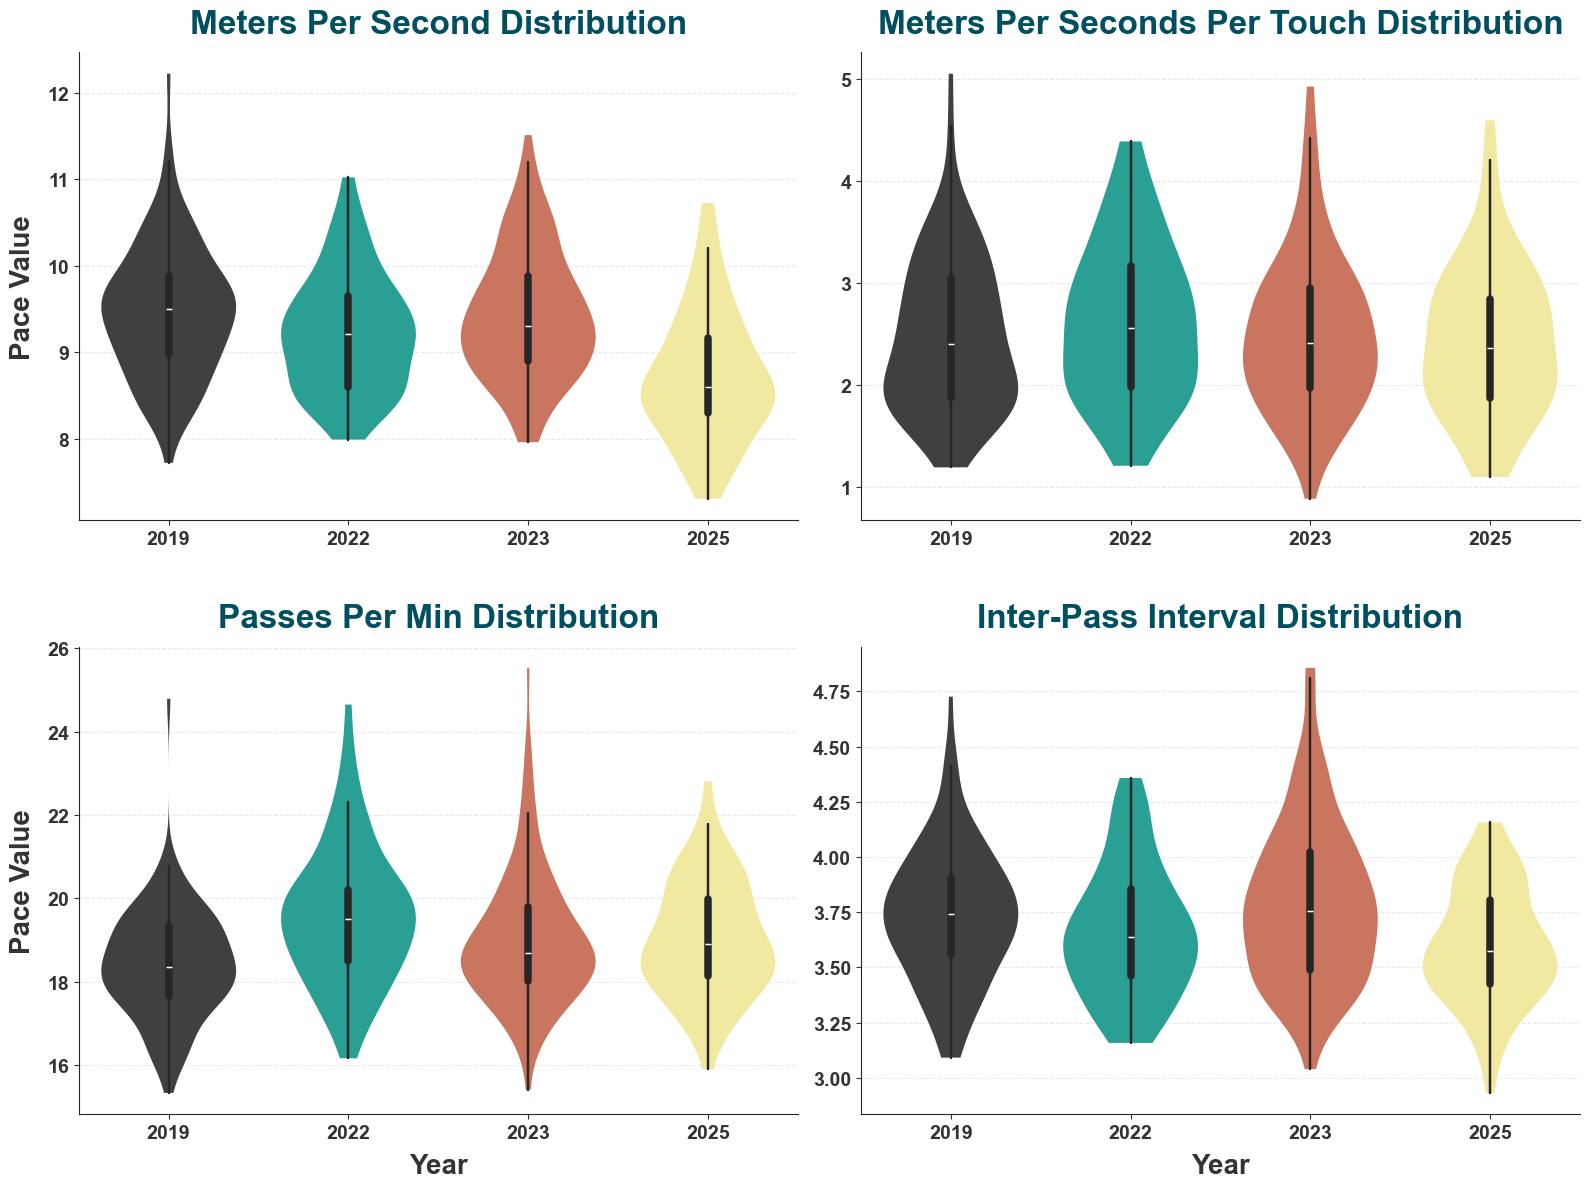

In [6]:
YEAR_COLOURS = ["#404040", "#16b3a4", "#dc6a4d", "#fff493"]
TEXT_COLOUR = "#333333"

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    for idx, (ax, method) in enumerate(zip(axes.flat, METHODS)):
        d = pop[pop["method"] == method].assign(
            year=lambda x: pd.Categorical(x["year"], categories=YEAR_ORDER, ordered=True))
        sns.violinplot(data=d, x="year", y="pop", hue="year", palette=YEAR_COLOURS, ax=ax,
                       linewidth=1.2, inner="box", dodge=False, legend=False, cut=0, width=0.75)
        for coll in ax.collections:                  # violins without outline
            coll.set_edgecolor("none")
            coll.set_linewidth(0)
        sns.despine(ax=ax)
        ax.grid(True, linestyle="--", alpha=0.4, axis="y", zorder=0)

        title = "Inter-Pass Interval" if method == "time_to_pass" else method.replace("_", " ").title()
        ax.set_title(f"{title} Distribution", fontsize=24, fontweight="bold", pad=14, color="#004F60")
        label = dict(fontsize=20, fontweight="bold", labelpad=8, color=TEXT_COLOUR)
        ax.set_xlabel("Year" if idx >= 2 else "", **label)          # bottom row only
        ax.set_ylabel("Pace Value" if idx % 2 == 0 else "", **label)  # left column only
        plt.setp(ax.get_xticklabels() + ax.get_yticklabels(), fontweight="bold")
        ax.tick_params(colors=TEXT_COLOUR, labelsize=14)
    plt.tight_layout(h_pad=4.0)
    fig.savefig(f"{FIG_DIR}/ECSS_Figure1_PoP_metrics_by_year.png", dpi=300, bbox_inches="tight")
    plt.show()

### 1.2 Linear mixed-effects models

The inter-pass interval is sign-inverted (`pop_signed`) so that higher values mean faster play for
every metric. Year is centred (`year_c`), and `meters_per_second` is the reference metric. All models
are fitted by REML, with random intercepts for team, match and competition.

- **Method model** `pop_signed ~ year_c + method`: how far each metric's estimate deviates from the
  reference, plus the competition and match variance components.
- **Interaction model** `pop_signed ~ year_c * method`: whether the temporal trend differs between
  metrics.
- **Separate models** `pop_signed ~ year_c`, one per metric: the slope per year with its 95% CI.

In [7]:
lmm = pop.assign(pop_signed=np.where(pop["method"] == "time_to_pass", -pop["pop"], pop["pop"]),
                 year_c=pop["year"] - pop["year"].mean())
VC = {"game": "0 + C(game_id)", "competition": "0 + C(competition_id)"}


def fit_lmm(formula, data):
    return smf.mixedlm(formula, data=data, groups="team_id", vc_formula=VC).fit(reml=True)


res_method = fit_lmm("pop_signed ~ year_c + method", lmm)
print(res_method.summary())

                        Mixed Linear Model Regression Results
Model:                      MixedLM           Dependent Variable:           pop_signed
No. Observations:           1424              Method:                       REML      
No. Groups:                 43                Scale:                        0.7143    
Min. group size:            12                Log-Likelihood:               -1917.4698
Max. group size:            104               Converged:                    Yes       
Mean group size:            33.1                                                      
--------------------------------------------------------------------------------------
                                        Coef.  Std.Err.    z     P>|z|  [0.025  0.975]
--------------------------------------------------------------------------------------
Intercept                                9.318    0.062  151.261 0.000   9.197   9.438
method[T.meters_per_seconds_per_touch]  -6.777    0.063 -106.981 0.0

In [8]:
res_inter = fit_lmm("pop_signed ~ year_c * method", lmm)
print(res_inter.summary())

                            Mixed Linear Model Regression Results
Model:                         MixedLM             Dependent Variable:             pop_signed
No. Observations:              1424                Method:                         REML      
No. Groups:                    43                  Scale:                          0.6853    
Min. group size:               12                  Log-Likelihood:                 -1902.1276
Max. group size:               104                 Converged:                      Yes       
Mean group size:               33.1                                                          
---------------------------------------------------------------------------------------------
                                               Coef.  Std.Err.    z     P>|z|  [0.025  0.975]
---------------------------------------------------------------------------------------------
Intercept                                       9.318    0.061  152.505 0.000   9.198   

In [9]:
trends = []
for method in METHODS:
    r = fit_lmm("pop_signed ~ year_c", lmm[lmm["method"] == method])
    lo, hi = r.conf_int().loc["year_c"]
    trends.append({"method": method, "n": int(r.nobs), "beta_year": r.params["year_c"],
                   "ci_lower": lo, "ci_upper": hi, "z": r.tvalues["year_c"], "p": r.pvalues["year_c"]})
trends = pd.DataFrame(trends)
trends.round(4).to_csv(f"{FIG_DIR}/ECSS_trends_by_metric.csv", index=False)
print("=== Slope per year by metric (separate models; inter-pass interval sign-inverted) ===")
print(trends.round(3).to_string(index=False))

=== Slope per year by metric (separate models; inter-pass interval sign-inverted) ===
                      method   n  beta_year  ci_lower  ci_upper      z     p
           meters_per_second 356     -0.071    -0.110    -0.032 -3.567 0.000
meters_per_seconds_per_touch 356     -0.022    -0.060     0.017 -1.109 0.268
              passes_per_min 356      0.068    -0.010     0.146  1.712 0.087
                time_to_pass 356      0.002    -0.013     0.018  0.290 0.772
